# 📧 01 - Exploratory Data Analysis (EDA)

Khám phá và phân tích thống kê dữ liệu email spam theo yêu cầu đề bài:
- **1. Tải và kiểm tra tổng quan cấu trúc dữ liệu** (Shape, Schema, Missing values)
- **2. Phân tích phân bố nhãn mục tiêu** (Tỷ lệ lớp Ham vs Spam, đánh giá mức độ mất cân bằng nhãn)
- **3. Thống kê đặc trưng văn bản** (Độ dài email, số lượng từ, tần suất ký tự số, URLs, chữ in hoa)
- **4. Phân tích tần suất từ và ký tự đặc trưng** (Word frequency, Character frequency: dấu '!', '$', từ khóa nhạy cảm)
- **5. Trực quan hóa so sánh đặc trưng giữa Spam và Ham**


Notebook này **không gọi trực tiếp các model có sẵn** như `sklearn.linear_model`,
`sklearn.svm`, `sklearn.naive_bayes`, `sklearn.ensemble`, `sklearn.model_selection`
hoặc `sklearn.feature_extraction`.

Các thuật toán được gọi từ package tự xây dựng của project:

```text
src/
├── data/
├── features/
├── models/
├── evaluation/
└── deployment/
```

Các thư viện tính toán nền tảng (NumPy/Pandas/Scipy/Matplotlib...) nếu có được sử dụng
thì được **ẩn bên trong `src/`**, còn notebook chỉ làm việc với API của project.

## IMPORT THƯ VIỆN & CẤU HÌNH HỆ THỐNG:
- Thêm đường dẫn project root vào sys.path để import các module từ src/.
  
- Import pandas, numpy, matplotlib.pyplot, seaborn.
  
- Import các module: src.config, src.data.loader, src.evaluation.visualization.
  
- Thiết lập random_state=42 cố định kết quả.

## 1. Tải và kiểm tra tổng quan cấu trúc dữ liệu
- Gọi src.data.loader.load_raw_data() để đọc file data/raw/spam.csv.

- Chuẩn hóa 2 cột cốt lõi: label và text.

- Gọi src.data.loader.explore_raw_data(df) kiểm tra missing values, tổng số mẫu.

- Hiển thị 5 dòng đầu và 5 dòng cuối của dữ liệu.


In [1]:
import sys
from pathlib import Path

# Tìm thư mục gốc của project
PROJECT_ROOT = Path.cwd().resolve()

# Nếu notebook đang nằm trong thư mục notebooks thì lùi lên một cấp
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Kiểm tra thư mục src có tồn tại không
print("Thư mục gốc:", PROJECT_ROOT)
print("Có thư mục src:", (PROJECT_ROOT / "src").is_dir())

# Thêm thư mục gốc vào đường dẫn tìm kiếm của Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

Thư mục gốc: C:\Users\hop98\Documents\Huyền\SpamClassifier_My_Task1\SpamClassifier_My_Task1\spam_classifier-main
Có thư mục src: True


In [5]:

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Xác định thư mục gốc của project
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Thêm project root vào sys.path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import các module của project
import src.config as config
from src.data.loader import load_raw_data, explore_raw_data
import src.evaluation.visualization as visualization

# Cố định kết quả ngẫu nhiên
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Cấu hình hiển thị
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)
print("Random state:", RANDOM_STATE)
print("Import thư viện thành công.")


Project root: C:\Users\hop98\Documents\Huyền\SpamClassifier_My_Task1\SpamClassifier_My_Task1\spam_classifier-main
Random state: 42
Import thư viện thành công.


In [10]:

# Đọc dữ liệu thô từ loader
raw_records = load_raw_data()

# Chuyển danh sách dictionary thành DataFrame
df = pd.DataFrame(raw_records)

print("Tải dữ liệu thành công.")
print(f"Số lượng bản ghi: {len(df):,}")
print("Kích thước dữ liệu:", df.shape)
print("Tên các cột:", df.columns.tolist())

display(df.head())


Tải dữ liệu thành công.
Số lượng bản ghi: 43,849
Kích thước dữ liệu: (43849, 4)
Tên các cột: ['source_id', 'label', 'text', 'raw_text']


,source_id,label,text,raw_text
0,1,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...","Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,2,ham,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,3,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,4,ham,U dun say so early hor... U c already then say...,U dun say so early hor... U c already then say...
4,5,ham,"Nah I don't think he goes to usf, he lives around here though","Nah I don't think he goes to usf, he lives around here though"


In [11]:

# Chuẩn hóa tên cột
df.columns = df.columns.str.strip().str.lower()

# Kiểm tra các cột bắt buộc
required_columns = {"label", "text"}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Thiếu các cột bắt buộc: {missing_columns}"
    )

# Chuẩn hóa nhãn và nội dung văn bản
df["label"] = (
    df["label"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

df["text"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print("Chuẩn hóa dữ liệu hoàn tất.")
print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nSố giá trị thiếu:")
print(df.isna().sum())

print("\nPhân bố nhãn:")
print(df["label"].value_counts(dropna=False))

print("\n5 dòng đầu:")
display(df.head(5))

print("\n5 dòng cuối:")
display(df.tail(5))


Chuẩn hóa dữ liệu hoàn tất.

Kiểu dữ liệu:
source_id    int64
label          str
text           str
raw_text       str
dtype: object

Số giá trị thiếu:
source_id    0
label        0
text         0
raw_text     0
dtype: int64

Phân bố nhãn:
label
ham         22820
spam        18834
             2192
label           2
category        1
Name: count, dtype: int64

5 dòng đầu:


,source_id,label,text,raw_text
0,1,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...","Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,2,ham,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,3,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,4,ham,U dun say so early hor... U c already then say...,U dun say so early hor... U c already then say...
4,5,ham,"Nah I don't think he goes to usf, he lives around here though","Nah I don't think he goes to usf, he lives around here though"



5 dòng cuối:


,source_id,label,text,raw_text
43844,43845,ham,- - - - - - - - - - - - - - - - - - - - - - forwarded by ami chokshi / corp / enron on 10 / 06 /...,- - - - - - - - - - - - - - - - - - - - - - forwarded by ami chokshi / corp / enron on 10 / 06 /...
43845,43846,ham,fyi these are the standards we are putting out there for gcp worldwide\n( draft at the moment - ...,fyi these are the standards we are putting out there for gcp worldwide\n( draft at the moment - ...
43846,43847,ham,metamucil baby original message parks joe mailto joe parks enron com sent friday march escapenum...,metamucil baby original message parks joe mailto joe parks enron com sent friday march escapenum...
43847,43848,spam,hi you have requested to change your myspace account email address current email address gnitpic...,hi you have requested to change your myspace account email address current email address gnitpic...
43848,43849,spam,"call computron\nfor\n: all your hp deskjet and laserjet printers , spare\nparts requirements .\n...","call computron\nfor\n: all your hp deskjet and laserjet printers , spare\nparts requirements .\n..."


In [12]:

import inspect

print(inspect.signature(explore_raw_data))
print(inspect.getsource(explore_raw_data))


(df: list[dict[str, typing.Any]]) -> dict[str, typing.Any]
def explore_raw_data(df: list[dict[str, Any]]) -> dict[str, Any]:
    """Thống kê trực tiếp từ dữ liệu, không gán trước tỷ lệ Ham/Spam."""
    counts = Counter(row.get('label', '') for row in df)
    valid = sum(counts.get(label, 0) for label in ('ham', 'spam'))
    lengths = [len(str(row.get('text') or '')) for row in df]
    words = [len(str(row.get('text') or '').split()) for row in df]
    def describe(values):
        return {'min': min(values), 'max': max(values), 'mean': mean(values),
                'median': median(values)} if values else {'min': 0, 'max': 0, 'mean': 0, 'median': 0}
    return {'n_rows': len(df), 'n_columns': len(df[0]) if df else 0,
            'missing_values': {key: sum(not str(row.get(key) or '').strip() for row in df)
                               for key in ('label', 'text')},
            'label_counts': dict(counts),
            'label_percentages': {label: 100 * counts.get(label, 0) / valid if

## 2. Phân tích phân bố nhãn (Target Class Distribution)

- Đếm số lượng mẫu của từng nhãn (df['label'].value_counts()).

- Tính tỷ lệ phần trăm (%) tương ứng của lớp Ham và lớp Spam.

- Vẽ biểu đồ Bar chart kết hợp Pie chart thể hiện mức độ mất cân bằng lớp.


TỔNG QUAN PHÂN BỐ NHÃN
Tổng số mẫu: 41,654


,Số lượng mẫu,Tỷ lệ (%)
label,,
ham,22820,54.78
spam,18834,45.22


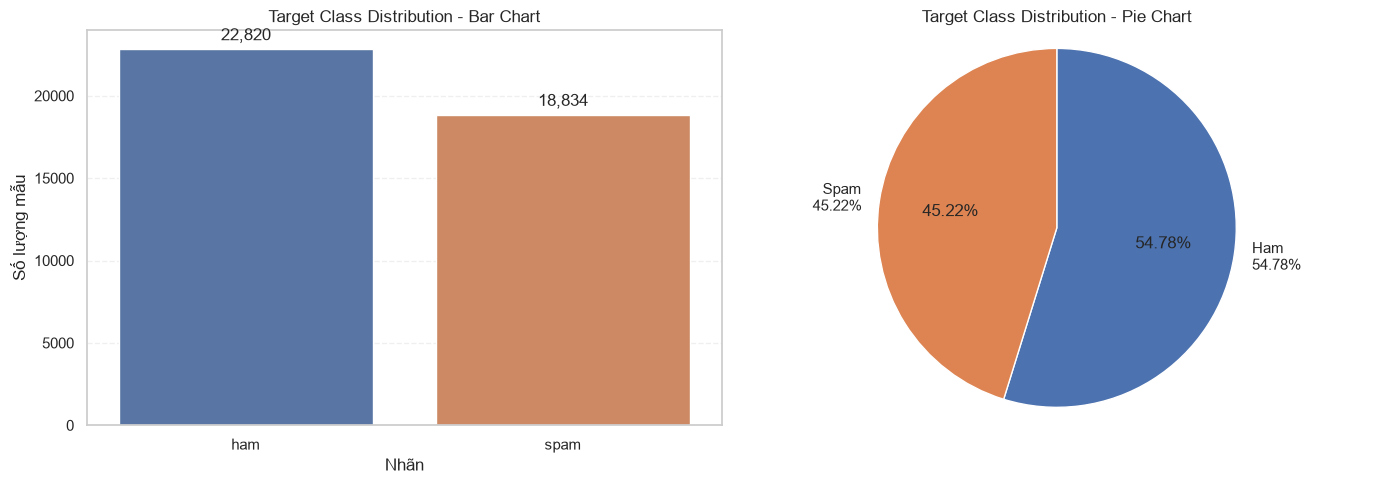

Tỷ lệ lớp lớn nhất / nhỏ nhất: 1.21:1
Nhận xét: Phân bố hai lớp tương đối cân bằng.


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đếm số lượng mẫu của từng nhãn
label_counts = df["label"].value_counts()

# Chuẩn hóa nhãn để bảo đảm thứ tự hiển thị nhất quán
label_order = ["ham", "spam"]
label_counts = label_counts.reindex(label_order, fill_value=0)

# 2. Tính tỷ lệ phần trăm của từng lớp
total_samples = label_counts.sum()
label_percentages = label_counts / total_samples * 100

# Hiển thị kết quả thống kê
distribution_df = pd.DataFrame({
    "Số lượng mẫu": label_counts,
    "Tỷ lệ (%)": label_percentages.round(2)
})

print("TỔNG QUAN PHÂN BỐ NHÃN")
print(f"Tổng số mẫu: {total_samples:,}")
display(distribution_df)

# 3. Vẽ Bar chart kết hợp Pie chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: số lượng mẫu của từng lớp
bars = sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    hue=label_counts.index,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Target Class Distribution - Bar Chart")
axes[0].set_xlabel("Nhãn")
axes[0].set_ylabel("Số lượng mẫu")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Hiển thị số lượng trên đầu mỗi cột
for bar in bars.patches:
    height = bar.get_height()
    axes[0].annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

# Pie chart: tỷ lệ phần trăm của từng lớp
axes[1].pie(
    label_counts.values,
    labels=[
        f"{label.capitalize()}\n{label_percentages[label]:.2f}%"
        for label in label_counts.index
    ],
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False
)

axes[1].set_title("Target Class Distribution - Pie Chart")
axes[1].axis("equal")

plt.tight_layout()
plt.show()

# 4. Đánh giá mức độ mất cân bằng lớp
if total_samples > 0 and (label_counts > 0).all():
    imbalance_ratio = label_counts.max() / label_counts.min()

    print(f"Tỷ lệ lớp lớn nhất / nhỏ nhất: {imbalance_ratio:.2f}:1")

    if imbalance_ratio < 1.5:
        print("Nhận xét: Phân bố hai lớp tương đối cân bằng.")
    else:
        print("Nhận xét: Dữ liệu có dấu hiệu mất cân bằng lớp.")
else:
    print("Không thể đánh giá tỷ lệ mất cân bằng: dữ liệu rỗng hoặc thiếu một lớp.")


## 3. Thống kê đặc trưng văn bản & độ dài email

- Tính độ dài ký tự và số lượng từ của từng email.
  
- Đếm số lượng chữ cái in hoa và tính tỷ lệ chữ hoa / tổng số chữ cái.
  
- Đếm tần suất ký tự đặc biệt (dấu chấm than '!', ký hiệu tiền tệ '$', chữ số).
  
- So sánh trung bình các đặc trưng này giữa nhóm Spam và nhóm Ham.
  
- Vẽ biểu đồ Histogram/KDE so sánh độ dài email giữa hai lớp.

Đã trích xuất đặc trưng văn bản.
Kích thước dữ liệu sau khi bổ sung đặc trưng: (43849, 12)


,label,text,char_count,word_count,uppercase_count,uppercase_ratio,exclamation_count,dollar_count,digit_count
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...",111.0,20.0,3.0,3.614458,0.0,0.0,0.0
1,ham,Ok lar... Joking wif u oni...,29.0,6.0,2.0,11.111111,0.0,0.0,0.0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,155.0,28.0,10.0,10.309278,0.0,0.0,25.0
3,ham,U dun say so early hor... U c already then say...,49.0,11.0,2.0,6.060606,0.0,0.0,0.0
4,ham,"Nah I don't think he goes to usf, he lives around here though",61.0,13.0,2.0,4.255319,0.0,0.0,0.0



SO SÁNH GIÁ TRỊ TRUNG BÌNH GIỮA HAM VÀ SPAM


,char_count,word_count,letter_count,uppercase_count,uppercase_ratio,exclamation_count,dollar_count,digit_count
label,,,,,,,,
ham,1533.90,233.83,1267.01,1.57,3.02,0.22,0.15,21.11
spam,1057.57,168.76,859.28,4.95,7.44,0.36,0.19,10.55


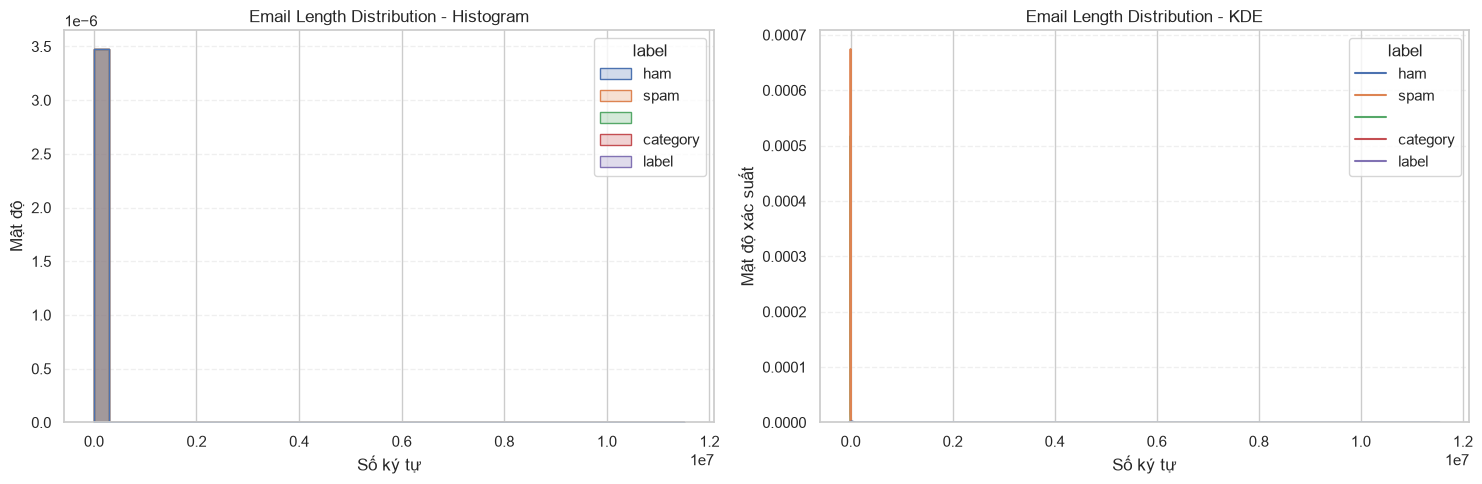


NHẬN XÉT SƠ BỘ
HAM: độ dài trung bình = 1533.90 ký tự, số từ trung bình = 233.83, tỷ lệ chữ hoa trung bình = 3.02%, số dấu ! trung bình = 0.22, số ký hiệu $ trung bình = 0.15, số chữ số trung bình = 21.11.
SPAM: độ dài trung bình = 1057.57 ký tự, số từ trung bình = 168.76, tỷ lệ chữ hoa trung bình = 7.44%, số dấu ! trung bình = 0.36, số ký hiệu $ trung bình = 0.19, số chữ số trung bình = 10.55.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re

# 1. Tính các đặc trưng cho từng email
def extract_text_features(text):
    text = str(text) if pd.notna(text) else ""

    # Tổng số ký tự
    char_count = len(text)

    # Số lượng từ: các chuỗi ký tự không chứa khoảng trắng
    word_count = len(text.split())

    # Tổng số chữ cái
    letter_count = sum(char.isalpha() for char in text)

    # Số chữ cái in hoa
    uppercase_count = sum(char.isupper() for char in text)

    # Tỷ lệ chữ hoa trên tổng số chữ cái (%)
    uppercase_ratio = (
        uppercase_count / letter_count * 100
        if letter_count > 0 else 0
    )

    # Số dấu chấm than
    exclamation_count = text.count("!")

    # Số ký hiệu tiền tệ $
    dollar_count = text.count("$")

    # Tổng số chữ số
    digit_count = sum(char.isdigit() for char in text)

    return pd.Series({
        "char_count": char_count,
        "word_count": word_count,
        "letter_count": letter_count,
        "uppercase_count": uppercase_count,
        "uppercase_ratio": uppercase_ratio,
        "exclamation_count": exclamation_count,
        "dollar_count": dollar_count,
        "digit_count": digit_count
    })


# 2. Trích xuất đặc trưng cho toàn bộ email
text_features = df["text"].apply(extract_text_features)

# Ghép đặc trưng với dữ liệu ban đầu
df_features = pd.concat([df, text_features], axis=1)

print("Đã trích xuất đặc trưng văn bản.")
print("Kích thước dữ liệu sau khi bổ sung đặc trưng:",
      df_features.shape)

# Xem thử các đặc trưng của 5 email đầu tiên
display(
    df_features[
        ["label", "text", "char_count", "word_count",
         "uppercase_count", "uppercase_ratio",
         "exclamation_count", "dollar_count", "digit_count"]
    ].head()
)


# 3. So sánh trung bình giữa Ham và Spam
feature_columns = [
    "char_count",
    "word_count",
    "letter_count",
    "uppercase_count",
    "uppercase_ratio",
    "exclamation_count",
    "dollar_count",
    "digit_count"
]

mean_comparison = (
    df_features.groupby("label")[feature_columns]
    .mean()
    .reindex(["ham", "spam"])
    .round(2)
)

print("\nSO SÁNH GIÁ TRỊ TRUNG BÌNH GIỮA HAM VÀ SPAM")
display(mean_comparison)


# 4. Vẽ Histogram + KDE so sánh độ dài email
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram: số ký tự
sns.histplot(
    data=df_features,
    x="char_count",
    hue="label",
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    kde=False,
    ax=axes[0]
)

axes[0].set_title("Email Length Distribution - Histogram")
axes[0].set_xlabel("Số ký tự")
axes[0].set_ylabel("Mật độ")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# KDE: phân bố độ dài email
sns.kdeplot(
    data=df_features,
    x="char_count",
    hue="label",
    common_norm=False,
    fill=False,
    warn_singular=False,
    ax=axes[1]
)

axes[1].set_title("Email Length Distribution - KDE")
axes[1].set_xlabel("Số ký tự")
axes[1].set_ylabel("Mật độ xác suất")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


# 5. Nhận xét sơ bộ về độ dài email
print("\nNHẬN XÉT SƠ BỘ")

for label in ["ham", "spam"]:
    subset = df_features[df_features["label"] == label]

    if not subset.empty:
        print(
            f"{label.upper()}: "
            f"độ dài trung bình = {subset['char_count'].mean():.2f} ký tự, "
            f"số từ trung bình = {subset['word_count'].mean():.2f}, "
            f"tỷ lệ chữ hoa trung bình = {subset['uppercase_ratio'].mean():.2f}%, "
            f"số dấu ! trung bình = {subset['exclamation_count'].mean():.2f}, "
            f"số ký hiệu $ trung bình = {subset['dollar_count'].mean():.2f}, "
            f"số chữ số trung bình = {subset['digit_count'].mean():.2f}."
        )


## 4. Phân tích tần suất từ vựng (Word Frequency & Keywords)

- Tách từ và đếm Top 20 từ xuất hiện nhiều nhất trong email Spam (free, claim, win, urgent, v.v.).
  
- Tách từ và đếm Top 20 từ xuất hiện nhiều nhất trong email Ham.
  
- Vẽ biểu đồ Bar chart nằm ngang so sánh Top từ khóa giữa 2 nhóm.

In [18]:

# 4.1. TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG SPAM

from collections import Counter
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Hàm tách từ
def tokenize_text(text):
    text = str(text).lower()
    return re.findall(r"\b[a-z0-9]+(?:'[a-z0-9]+)*\b", text)

# Lọc email Spam
spam_texts = df.loc[df["label"] == "spam", "text"]

# Tách từ và đếm tần suất
spam_counter = Counter()

for text in spam_texts:
    spam_counter.update(tokenize_text(text))

# Lấy Top 20 từ phổ biến nhất
top20_spam = pd.DataFrame(
    spam_counter.most_common(20),
    columns=["Từ khóa", "Tần suất"]
)

print("TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG SPAM")
display(top20_spam)


TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG SPAM


,Từ khóa,Tần suất
0,escapenumber,175333
1,the,83191
2,to,60152
3,and,42912
4,of,40774
5,a,39972
6,in,29331
7,escapelong,24717
8,you,23248
9,for,23190


In [19]:

# 4.2. TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG HAM

# Lọc email Ham
ham_texts = df.loc[df["label"] == "ham", "text"]

# Tách từ và đếm tần suất
ham_counter = Counter()

for text in ham_texts:
    ham_counter.update(tokenize_text(text))

# Lấy Top 20 từ phổ biến nhất
top20_ham = pd.DataFrame(
    ham_counter.most_common(20),
    columns=["Từ khóa", "Tần suất"]
)

print("TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG HAM")
display(top20_ham)


TOP 20 TỪ XUẤT HIỆN NHIỀU NHẤT TRONG HAM


,Từ khóa,Tần suất
0,escapenumber,216069
1,the,104144
2,to,72069
3,and,51484
4,of,48250
5,a,45291
6,in,36145
7,escapelong,28807
8,you,28133
9,for,27812


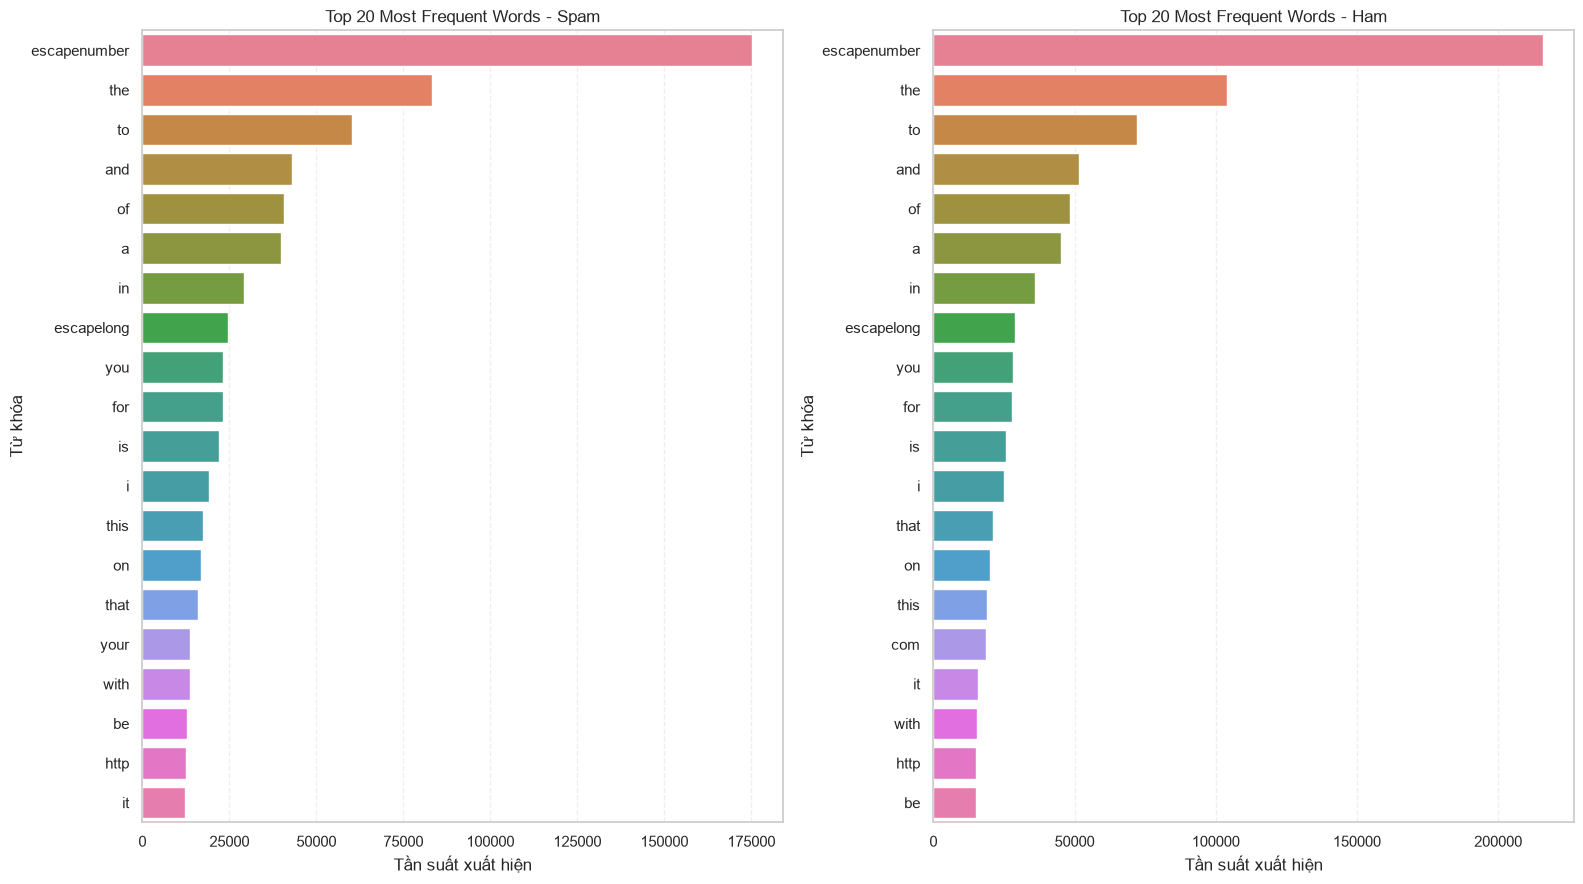

In [20]:

# 4.3. BIỂU ĐỒ TOP 20 TỪ KHÓA CỦA SPAM VÀ HAM

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Biểu đồ Top 20 Spam
sns.barplot(
    data=top20_spam,
    x="Tần suất",
    y="Từ khóa",
    hue="Từ khóa",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top 20 Most Frequent Words - Spam")
axes[0].set_xlabel("Tần suất xuất hiện")
axes[0].set_ylabel("Từ khóa")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)

# Biểu đồ Top 20 Ham
sns.barplot(
    data=top20_ham,
    x="Tần suất",
    y="Từ khóa",
    hue="Từ khóa",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top 20 Most Frequent Words - Ham")
axes[1].set_xlabel("Tần suất xuất hiện")
axes[1].set_ylabel("Từ khóa")
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()
